In [26]:
import pandas as pd
import seaborn as sns
from ast import literal_eval
from datasets import load_dataset
import matplotlib.pyplot as plt


dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].fillna('[]')
df['job_skills'] = df['job_skills'].apply(literal_eval)

In [27]:
df_data_eng_us = df[(df['job_title_short'] == 'Data Engineer') & (df['job_country'] == 'United States')].copy()

df_data_eng_us = df_data_eng_us.dropna(subset=['salary_year_avg'])

df_data_eng_us_exp = df_data_eng_us.explode('job_skills')

df_data_eng_us_exp[['salary_year_avg', 'job_skills']].head(5)


,salary_year_avg,job_skills
92,120000.0,sql
92,120000.0,python
146,129500.0,golang
146,129500.0,scala
146,129500.0,python


In [29]:
import ast

df_technology = df['job_type_skills'].copy()

# remove duplicates
df_technology = df_technology.drop_duplicates()

# remove NaN values
df_technology = df_technology.dropna()

# combine all dictionaries into one
technology_dict = {}
for row in df_technology:
    row_dict = ast.literal_eval(row)  # convert string to dictionary
    for key, value in row_dict.items():
        if key in technology_dict:  # if key already exists in technology_dict, add value to existing list
            technology_dict[key] += value
        else:                       # if key does not exist in technology_dict, add key and value
            technology_dict[key] = value

# remove duplicates by converting values to set then back to list
for key, value in technology_dict.items():
    technology_dict[key] = list(set(value))

technology_dict

{'analyst_tools': ['alteryx',
  'ssis',
  'powerpoint',
  'power bi',
  'tableau',
  'cognos',
  'qlik',
  'spss',
  'word',
  'spreadsheet',
  'sheets',
  'splunk',
  'powerbi',
  'nuix',
  'outlook',
  'dax',
  'datarobot',
  'microstrategy',
  'ms access',
  'ssrs',
  'msaccess',
  'esquisse',
  'visio',
  'looker',
  'sas',
  'sap',
  'excel',
  'sharepoint'],
 'programming': ['c++',
  'groovy',
  'lua',
  'python',
  'rust',
  'erlang',
  'delphi',
  'typescript',
  'nosql',
  'c',
  'lisp',
  'matlab',
  'html',
  'shell',
  'vba',
  'perl',
  'scala',
  'mongodb',
  'fortran',
  'c#',
  'sql',
  'f#',
  'apl',
  'visual basic',
  'ocaml',
  'haskell',
  'dart',
  'elixir',
  'no-sql',
  'cobol',
  'julia',
  'php',
  'clojure',
  'golang',
  'ruby',
  'sass',
  'swift',
  'css',
  't-sql',
  'mongo',
  'vb.net',
  'java',
  'visualbasic',
  'bash',
  'powershell',
  'crystal',
  'go',
  'kotlin',
  'r',
  'assembly',
  'objective-c',
  'javascript',
  'solidity',
  'pascal',
  '

In [30]:
df_sample = df_data_eng_us_exp.groupby('job_skills')['salary_year_avg'].agg(['count', 'median']).sort_values(by='count', ascending=False)

df_sample = df_sample.rename(columns={'count': 'skill_count', 'median': 'median_salary'})

de_j_c = len(df_data_eng_us)

df_sample['skill_percent'] = df_sample['skill_count'] / de_j_c * 100

skill_percent = 14

df_sample_h_d = df_sample[df_sample['skill_percent'] > skill_percent]

df_sample_h_d

,skill_count,median_salary,skill_percent
job_skills,,,
sql,2110,125000.00000,72.384220
python,2007,127794.50000,68.850772
aws,1313,131000.00000,45.042882
spark,968,137410.15625,33.207547
azure,961,125000.00000,32.967410
snowflake,765,130700.00000,26.243568
java,732,137000.00000,25.111492
kafka,536,145000.00000,18.387650
nosql,519,140000.00000,17.804460


In [33]:
df_technology = pd.DataFrame(list(technology_dict.items()), columns=['technology', 'skills'])

df_technology = df_technology.explode('skills')

df_plot = df_sample_h_d.merge(df_technology, left_on='job_skills', right_on='skills')

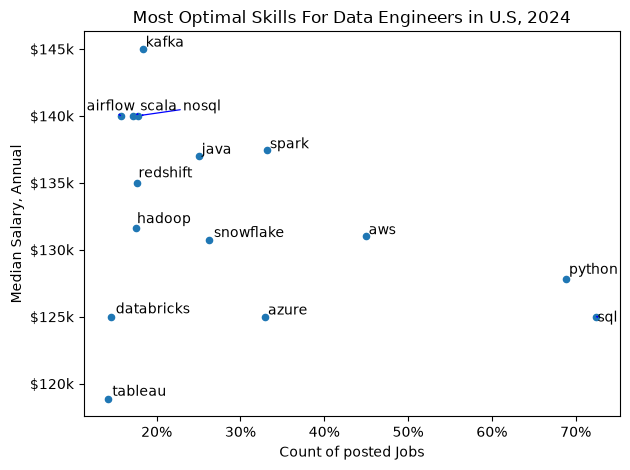

In [ ]:
from adjustText import adjust_text
from matplotlib.ticker import PercentFormatter

texts = []
for i, txt in enumerate(df_sample_h_d.index):
    texts.append(plt.text(df_sample_h_d.skill_percent.iloc[i], df_sample_h_d.median_salary.iloc[i], txt ))


adjust_text(texts, arrowprops=dict(arrowstyle='->', color='b', lw='0.9'))

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}k'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
plt.xlabel('Count of posted Jobs')
plt.ylabel('Median Salary, Annual')
plt.title('Most Optimal Skills For Data Engineers in U.S, 2024')
plt.tight_layout()
plt.show()

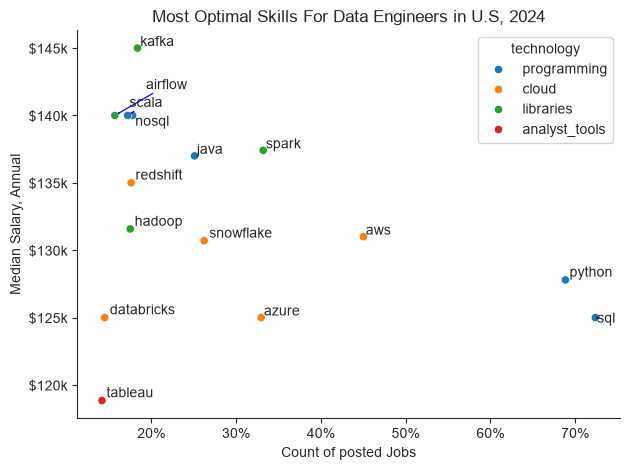

In [42]:
from adjustText import adjust_text
from matplotlib.ticker import PercentFormatter

#df_plot.plot(kind='scatter', x='skill_percent', y ='median_salary')
sns.scatterplot(
    data=df_plot,
    x='skill_percent',
    y='median_salary',
    hue='technology'
                )

sns.despine()
sns.set_style('ticks')
texts = []
for i, txt in enumerate(df_plot.skills):
    texts.append(plt.text(df_plot.skill_percent.iloc[i], df_plot.median_salary.iloc[i], txt ))


adjust_text(texts, arrowprops=dict(arrowstyle='->', color='b', lw='0.9'))

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}k'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
plt.xlabel('Count of posted Jobs')
plt.ylabel('Median Salary, Annual')
plt.title('Most Optimal Skills For Data Engineers in U.S, 2024')
plt.tight_layout()
plt.show()